

<!-- FLOWMLLAB_COLAB_LAUNCH_V1 -->
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ehsan-Roohi/FlowMLLab/blob/main/notebooks/week02/AI_in_Fluids_Week2_Colab_Expanded.ipynb)
# AI in Fluids - Week 2 Colab
## Neural networks and rarefied-flow surrogates

This notebook supports the Week-2 lecture.  It is designed to make a neural network less mysterious.

You will:

1. compute a one-neuron prediction by hand in Python,
2. perform one gradient-descent update,
3. plot activation functions,
4. generate a synthetic rarefied-flow dataset,
5. train simple baselines and a small DNN,
6. evaluate numerical errors,
7. perform physical validation checks.

The rarefied-flow dataset in this notebook is synthetic.  It is a teaching model, not a substitute for DSMC, Boltzmann, or experimental data.


## Start here: what you will build

You will first update one neuron by hand, then compare three predictors of a synthetic rarefied-flow quantity: polynomial regression, nearest neighbors and a deep neural network (DNN). Finally, you will inspect their behavior along a controlled physical parameter sweep.

| Stage | Run | What to check before continuing |
|---|---|---|
| Understand an update | Sections 0-3 | Reproduce the first prediction and explain why the loss decreases. |
| Prepare the data | Sections 4-7 | Identify four features, one target, three data subsets and training-only scalers. |
| Fit the models | Sections 8-10 | Compare two baselines with a 4-32-32-1 network; identify Adam's learning rate. |
| Interpret predictions | Sections 11-12 | Read errors in original target units and compare profiles with the synthetic reference. |
| Test a new range | Section 13 | Explain what in-range validation can and cannot tell you about extrapolation. |

**First run:** choose **Runtime > Run all** in Colab and retain the default training settings. TensorFlow training takes longer than the small NumPy exercises; elapsed time depends on the runtime. Attempt the optional multiple-rate exercise after the baseline works. Re-running a downstream cell after changing data or training settings can reuse old variables: rerun the affected stages in order.

**Data provenance:** the target is generated by the formula in Section 4. It is a teaching surrogate, not measured data or a validated Boltzmann/DSMC solution. Agreement with this formula tests this learning exercise; it does not validate a real rarefied-flow model.

**Deliverables:** the one-neuron calculation, a model-error table, a physical profile comparison, an interpretation of training/validation histories, and an extrapolation discussion. The final exercise specifies which settings and evidence to report.



## 0. Imports

Run this cell first.  Google Colab normally includes TensorFlow, NumPy, scikit-learn, pandas, and Matplotlib.


In [1]:
# FLOWMLLAB_COLAB_BOOTSTRAP_V1
# In Colab this cell obtains the complete repository and installs the tested package.
# In a local checkout it leaves the active environment and working directory unchanged.
from pathlib import Path as _FlowMLLabPath
import os as _flowmllab_os
import subprocess as _flowmllab_subprocess
import sys as _flowmllab_sys

if "google.colab" in _flowmllab_sys.modules or _flowmllab_os.environ.get("COLAB_RELEASE_TAG"):
    _flowmllab_root = _FlowMLLabPath("/content/FlowMLLab")
    if not (_flowmllab_root / ".git").is_dir():
        _flowmllab_subprocess.run(
            [
                "git", "clone", "--depth", "1",
                "https://github.com/Ehsan-Roohi/FlowMLLab.git", str(_flowmllab_root),
            ],
            check=True,
        )
    _flowmllab_subprocess.run(
        [
            _flowmllab_sys.executable, "-m", "pip", "install", "-q", "-e",
            f"{_flowmllab_root}[test]",
        ],
        check=True,
    )
    _flowmllab_notebook_dir = _flowmllab_root / "notebooks/week02"
    _flowmllab_os.chdir(_flowmllab_notebook_dir)
    for _flowmllab_path in (_flowmllab_root, _flowmllab_notebook_dir):
        if str(_flowmllab_path) not in _flowmllab_sys.path:
            _flowmllab_sys.path.insert(0, str(_flowmllab_path))
    print("FlowMLLab ready:", _flowmllab_root)


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

np.random.seed(7)
tf.random.set_seed(7)

plt.rcParams.update({"figure.figsize": (6,4), "font.size": 11})
print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.20.0


## 1. One neuron: forward pass

A single linear-output neuron is

$$
o = w_1 x_1 + w_2 x_2 + b,
$$

where:

- $o$ is the model output,
- $x_1 = \log_{10}(Kn)$ is a logarithmic Knudsen-number feature,
- $x_2 = \alpha$ is the accommodation coefficient,
- $w_1,w_2$ are weights,
- $b$ is the bias.

Use the numerical values from the lecture.

In [2]:

# Features and target for one training sample
x1 = -2.0       # log10(Kn), so Kn = 1e-2
x2 = 0.8        # accommodation coefficient alpha
t = 0.25        # target normalized mass-flow correction

# Initial parameters
w1 = 0.20
w2 = -0.10
b = 0.05

# Forward pass
o = w1*x1 + w2*x2 + b
e = t - o
C = 0.5*(t - o)**2

print(f"prediction o = {o:.5f}")
print(f"error e = t - o = {e:.5f}")
print(f"loss C = 0.5*(t-o)^2 = {C:.5f}")


prediction o = -0.43000
error e = t - o = 0.68000
loss C = 0.5*(t-o)^2 = 0.23120


## 2. One gradient-descent update

For this linear-output neuron with squared-error loss,

$$
w_j \leftarrow w_j + \eta (t-o)x_j, \qquad b \leftarrow b + \eta(t-o),
$$

where $\eta$ is the learning rate and $j$ is the feature index.

In [3]:

eta = 0.05  # learning rate

w1_new = w1 + eta*(t-o)*x1
w2_new = w2 + eta*(t-o)*x2
b_new  = b  + eta*(t-o)

o_new = w1_new*x1 + w2_new*x2 + b_new
C_new = 0.5*(t - o_new)**2

print("Old parameters:", w1, w2, b)
print("New parameters:", w1_new, w2_new, b_new)
print(f"old prediction = {o:.5f}, old loss = {C:.5f}")
print(f"new prediction = {o_new:.5f}, new loss = {C_new:.5f}")


Old parameters: 0.2 -0.1 0.05
New parameters: 0.132 -0.0728 0.084
old prediction = -0.43000, old loss = 0.23120
new prediction = -0.23824, new loss = 0.11919



### Question
Did the prediction move closer to the target?  Explain in one sentence in your report.


### Experiment: learning rate for the neuron you just calculated

Use the same sample, target and initial parameters from Section 1. Pack the weights and bias into $\theta=(w_1,w_2,b)$ and the inputs into $\widetilde x=(x_1,x_2,1)$; the final 1 represents the bias input. With $o=\theta\cdot\widetilde x$,

$$
C=\frac12(o-t)^2,\qquad \nabla_\theta C=(o-t)\widetilde x.
$$

For repeated gradient descent on this **single fixed sample**, the prediction error follows

$$
o_{k+1}-t=\left(1-\eta\|\widetilde x\|^2\right)(o_k-t).
$$

Here $k$ counts parameter updates and $\|\widetilde x\|^2=(-2)^2+0.8^2+1^2=5.64$. The error decays when $0<\eta<2/5.64\approx0.3546$. This differs from the later scalar quadratic's limit because its curvature differs. Neither limit is a universal Adam setting.

**Before running:** predict which of 0.01, 0.05, 0.30 and 0.40 will approach the target monotonically, approach with oscillations, or diverge. Every curve starts from the same parameters. This is a numerical exercise on one sample, not network training.

Single-sample learning-rate limit: 0 < eta < 0.354610


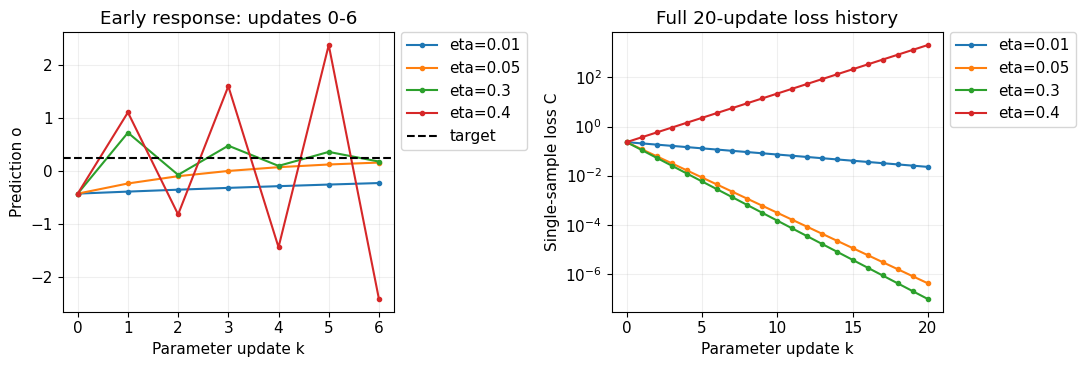

At eta=0.05, the first prediction is -0.23824


In [4]:
import numpy as np
import matplotlib.pyplot as plt

sample = np.array([x1, x2, 1.0])
initial_parameters = np.array([w1, w2, b], dtype=float)
curvature = sample @ sample
print(f"Single-sample learning-rate limit: 0 < eta < {2/curvature:.6f}")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for trial_rate in [0.01, 0.05, 0.30, 0.40]:
    parameters = initial_parameters.copy()
    predictions = [parameters @ sample]
    for update in range(20):
        prediction = parameters @ sample
        parameters -= trial_rate * (prediction-t) * sample
        predictions.append(parameters @ sample)
    predictions = np.asarray(predictions)
    axes[0].plot(predictions[:7], marker=".", label=f"eta={trial_rate}")
    axes[1].semilogy(0.5*(predictions-t)**2, marker=".", label=f"eta={trial_rate}")
axes[0].axhline(t, color="black", linestyle="--", label="target")
axes[0].set(xlabel="Parameter update k", ylabel="Prediction o",
            title="Early response: updates 0-6")
axes[1].set(xlabel="Parameter update k", ylabel="Single-sample loss C",
            title="Full 20-update loss history")
for ax in axes:
    ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0); ax.grid(alpha=0.2)
fig.tight_layout(); plt.show()
first_parameters = initial_parameters - 0.05*(initial_parameters @ sample-t)*sample
assert np.isclose(first_parameters @ sample, -0.23824, atol=1e-12)
print("At eta=0.05, the first prediction is", first_parameters @ sample)



## 3. Activation functions

Activation functions introduce nonlinearity.  Without nonlinear activations, stacked layers reduce to one linear map.


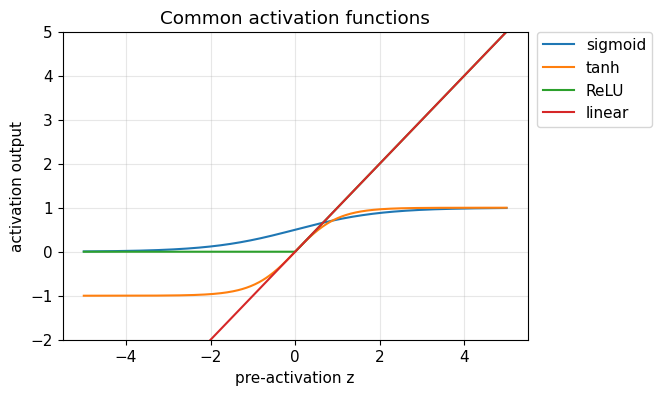

In [5]:

z = np.linspace(-5, 5, 500)
sigmoid = 1/(1 + np.exp(-z))
tanh = np.tanh(z)
relu = np.maximum(0, z)
linear = z

plt.figure()
plt.plot(z, sigmoid, label="sigmoid")
plt.plot(z, tanh, label="tanh")
plt.plot(z, relu, label="ReLU")
plt.plot(z, linear, label="linear")
plt.ylim(-2, 5)
plt.xlabel("pre-activation z")
plt.ylabel("activation output")
plt.title("Common activation functions")
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0)
plt.grid(True, alpha=0.3)
plt.show()


## 4. Synthetic rarefied-flow dataset

We use the synthetic relation

$$
Q^* = \left(1-\frac{1}{\Pi}\right)
\left[1 + C_s\frac{2-\alpha}{\alpha}\frac{Kn}{1+Kn}\right]
\Theta^{-1/2}
\left[1+C_r\tanh\left(\log_{10}Kn+1\right)\right] + \epsilon.
$$

Definitions:

- $Q^*$: normalized mass-flow proxy,
- $Kn$: Knudsen number,
- $\alpha$: accommodation coefficient,
- $\Pi = p_{in}/p_{out}$: pressure ratio,
- $\Theta = T_w/T_0$: wall-to-reference temperature ratio,
- $C_s$: slip-strength coefficient,
- $C_r$: rarefaction-transition coefficient,
- $\epsilon$: small noise term.

In [6]:

def synthetic_Q(log10_Kn, alpha, Pi, Theta, noise_std=0.01, seed=None):
    rng = np.random.default_rng(seed)
    Kn = 10**log10_Kn
    Cs = 1.25
    Cr = 0.10
    clean = (1 - 1/Pi) * (1 + Cs*((2-alpha)/alpha)*(Kn/(1+Kn))) * (Theta**(-0.5)) * (1 + Cr*np.tanh(log10_Kn + 1))
    noise = rng.normal(0.0, noise_std, size=np.shape(clean))
    return clean + noise

N = 5000
rng = np.random.default_rng(42)

log10_Kn = rng.uniform(-4.0, 1.5, N)       # Kn from 1e-4 to about 31.6
alpha = rng.uniform(0.6, 1.0, N)           # accommodation coefficient
Pi = rng.uniform(1.1, 5.0, N)              # pressure ratio p_in / p_out
Theta = rng.uniform(0.7, 1.5, N)           # wall/reference temperature ratio

Qstar = synthetic_Q(log10_Kn, alpha, Pi, Theta, noise_std=0.01, seed=5)

df = pd.DataFrame({
    "log10_Kn": log10_Kn,
    "Kn": 10**log10_Kn,
    "alpha": alpha,
    "Pi": Pi,
    "Theta": Theta,
    "Qstar": Qstar
})

df.head()


,log10_Kn,Kn,alpha,Pi,Theta,Qstar
0,0.256758,1.806169,0.687260,3.910841,0.978044,2.063499
1,-1.586169,0.025932,0.865171,3.873827,0.782246,0.814252
2,0.722289,5.275803,0.906745,1.890511,0.941655,1.201174
3,-0.164476,0.684738,0.666654,1.242956,1.345365,0.367181
4,-3.482025,0.000330,0.617543,2.284818,1.094784,0.496244


## 5. Classify rarefaction regimes

Use the approximate ranges:

- continuum: $Kn < 10^{-3}$,
- slip: $10^{-3} \le Kn < 10^{-1}$,
- transition: $10^{-1} \le Kn < 10$,
- free molecular: $Kn \ge 10$.

In [7]:

def classify_regime(Kn):
    Kn = np.asarray(Kn)
    labels = np.empty(Kn.shape, dtype=object)
    labels[Kn < 1e-3] = "continuum"
    labels[(Kn >= 1e-3) & (Kn < 1e-1)] = "slip"
    labels[(Kn >= 1e-1) & (Kn < 10)] = "transition"
    labels[Kn >= 10] = "free molecular"
    return labels

df["regime"] = classify_regime(df["Kn"].values)
df["regime"].value_counts()


regime
slip              1843
transition        1773
continuum          931
free molecular     453
Name: count, dtype: int64

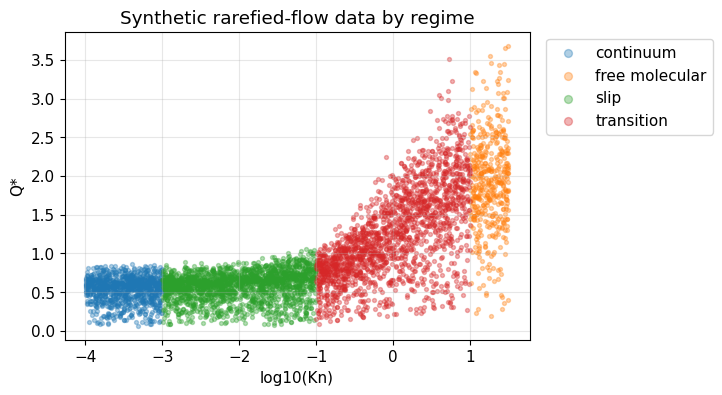

In [8]:

plt.figure()
for reg, g in df.groupby("regime"):
    plt.scatter(g["log10_Kn"], g["Qstar"], s=8, alpha=0.35, label=reg)
plt.xlabel("log10(Kn)")
plt.ylabel("Q*")
plt.title("Synthetic rarefied-flow data by regime")
plt.legend(markerscale=2, loc='upper left', bbox_to_anchor=(1.02, 1))
plt.grid(True, alpha=0.3)
plt.show()


## 6. Feature matrix and target vector

The feature matrix is

$$
X = [\log_{10}Kn,\alpha,\Pi,\Theta].
$$

The target vector is $y=Q^*$.

In [9]:

feature_cols = ["log10_Kn", "alpha", "Pi", "Theta"]
X = df[feature_cols].values.astype("float32")
y = df["Qstar"].values.astype("float32").reshape(-1, 1)

X_train, X_temp, y_train, y_temp, reg_train, reg_temp = train_test_split(
    X, y, df["regime"].values, test_size=0.30, random_state=10
)
X_val, X_test, y_val, y_test, reg_val, reg_test = train_test_split(
    X_temp, y_temp, reg_temp, test_size=0.50, random_state=10
)

scaler_X = StandardScaler().fit(X_train)
scaler_y = StandardScaler().fit(y_train)

X_train_s = scaler_X.transform(X_train)
X_val_s = scaler_X.transform(X_val)
X_test_s = scaler_X.transform(X_test)

y_train_s = scaler_y.transform(y_train)
y_val_s = scaler_y.transform(y_val)
y_test_s = scaler_y.transform(y_test)

print("train/val/test shapes:", X_train.shape, X_val.shape, X_test.shape)


train/val/test shapes: (3500, 4) (750, 4) (750, 4)


### Read the arrays and prevent data leakage

One row of $X$ is one flow case. Its columns are ordered as $[\log_{10}Kn,\alpha,\Pi,\Theta]$. The corresponding row of $y$ contains one value of $Q^*$, so the shapes are $(N,4)$ and $(N,1)$.

The split keeps 70% for training, 15% for validation and 15% for final testing. A scaler learns its mean and standard deviation **only from training data**:

$$
z_j=\frac{x_j-\mu_{j,\mathrm{train}}}{\sigma_{j,\mathrm{train}}}.
$$

Use those same statistics on validation, test and new inputs. Standardization changes the numerical scale, not the physical meaning of a feature. Predictions from the neural network are in standardized target units; `scaler_y.inverse_transform` returns $Q^*$ before physical plots and error metrics are evaluated.

The checks below use the arrays actually created above. Near-zero means are expected for standardized **training** features; validation means need not be zero. A random split measures interpolation within the sampled distribution and does not guarantee generalization to a new physical regime.

In [10]:
assert X_train.shape[1] == 4 and y_train.shape[1] == 1
assert len(X_train) + len(X_val) + len(X_test) == len(X)
assert np.isfinite(X_train_s).all() and np.isfinite(y_train_s).all()
np.testing.assert_allclose(scaler_X.mean_, X_train.mean(axis=0, dtype=np.float64))
np.testing.assert_allclose(X_train_s.mean(axis=0), 0.0, atol=2e-6)
np.testing.assert_allclose(scaler_y.inverse_transform(y_train_s), y_train, atol=1e-6)
print("Rows and shapes:")
for subset, features, targets in [("train", X_train, y_train),
                                   ("validation", X_val, y_val),
                                   ("test", X_test, y_test)]:
    print(f"{subset:10s}: X{features.shape}, y{targets.shape}")
print("Training feature means after standardization:", X_train_s.mean(axis=0))


Rows and shapes:
train     : X(3500, 4), y(3500, 1)
validation: X(750, 4), y(750, 1)
test      : X(750, 4), y(750, 1)
Training feature means after standardization: [-1.1107751e-08  3.8385391e-08 -4.0871756e-10 -2.4692820e-08]



## 7. Error metrics


Let $y_i$ be a test target and $\widehat y_i$ its prediction, both in original $Q^*$ units. For $N_{test}$ cases,

$$
\mathrm{RMSE}=\sqrt{\frac{1}{N_{test}}\sum_i(\widehat y_i-y_i)^2},\qquad
\mathrm{MAE}=\frac{1}{N_{test}}\sum_i|\widehat y_i-y_i|,
$$

$$
\mathrm{Relative}\ L_2=\frac{\sqrt{\sum_i(\widehat y_i-y_i)^2}}{\sqrt{\sum_i y_i^2}}.
$$

RMSE gives more weight to large errors; MAE is an average absolute discrepancy. Relative $L_2$ compares the error-vector magnitude with the target-vector magnitude. It is a ratio: multiply by 100 to express it as a percentage. The training loss is MSE on standardized targets, so its numerical value should not be compared directly with RMSE in original target units.

In [11]:

def metrics(y_true, y_pred):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    rel_l2 = np.linalg.norm(y_true - y_pred) / np.linalg.norm(y_true)
    return rmse, mae, rel_l2



## 8. Baseline 1: polynomial regression


In [12]:

poly_model = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=3, include_bias=False),
    Ridge(alpha=1e-6)
)
poly_model.fit(X_train, y_train.ravel())
poly_pred = poly_model.predict(X_test).reshape(-1, 1)

poly_metrics = metrics(y_test, poly_pred)
print("Polynomial regression metrics (RMSE, MAE, RelL2):", poly_metrics)


Polynomial regression metrics (RMSE, MAE, RelL2): (np.float64(0.08643767980793382), 0.06908715516328812, np.float32(0.07898161))



## 9. Baseline 2: nearest-neighbor/local interpolation


In [13]:

knn_model = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=8, weights="distance"))
knn_model.fit(X_train, y_train.ravel())
knn_pred = knn_model.predict(X_test).reshape(-1, 1)

knn_metrics = metrics(y_test, knn_pred)
print("KNN/local interpolation metrics (RMSE, MAE, RelL2):", knn_metrics)


KNN/local interpolation metrics (RMSE, MAE, RelL2): (np.float64(0.07021599112103526), 0.04378554231474546, np.float64(0.0641591935004118))



## 10. DNN surrogate

The DNN receives four inputs and predicts one scalar output.


### Learning rate and Adam: what changes at each update?

A **trainable parameter** is a weight or bias learned from data. A **physical parameter**, such as Reynolds or Knudsen number, describes the flow. A **hyperparameter**, such as learning rate, batch size or network width, is chosen for training and is not updated by Adam. Collect all parameters in $\theta$. A **batch** is a subset of the training samples; its mean squared error is $C_B(\theta)$. The gradient $g_k=\nabla_\theta C_B(\theta_{k-1})$ gives the local uphill direction. An optimizer moves the parameters downhill. Here $k=1,2,\ldots$ counts **parameter updates**, not epochs.

For gradient descent, the update is

$$
\theta_k=\theta_{k-1}-\eta g_k.
$$

The learning rate $\eta$ sets the step scale. For the particular scalar loss $C(\theta)=\tfrac12(\theta-3)^2$, $g=\theta-3$. Starting from $\theta_0=1$, one update with $\eta=0.5$ gives $1-0.5(-2)=2$. The error obeys $e_k=(1-\eta)e_{k-1}$, so this **quadratic gradient-descent example** converges for $0<\eta<2$. That bound is not a general rule for Adam or a neural network.

Adam maintains two arrays, each with the same shape as the parameters. With $m_0=v_0=0$,

$$
m_k=\beta_1m_{k-1}+(1-\beta_1)g_k,
$$

$$
v_k=\beta_2v_{k-1}+(1-\beta_2)g_k^2.
$$

All products, squares, square roots and divisions here act **component by component**. $m_k$ averages recent signed gradients; $v_k$ averages their squares. The name $v_k$ here is optimizer memory, not a fluid velocity. It averages squared gradients; it is not a statistical variance. Starting these averages at zero biases their early magnitudes downward. Bias correction gives

$$
\widehat m_k=\frac{m_k}{1-\beta_1^k},\qquad \widehat v_k=\frac{v_k}{1-\beta_2^k}.
$$

The familiar Adam form is $\theta_k=\theta_{k-1}-\eta\widehat m_k/(\sqrt{\widehat v_k}+\epsilon_{\mathrm{alg}})$. The **Keras implementation used below** places its small positive constant differently:

$$
\alpha_k=\eta\frac{\sqrt{1-\beta_2^k}}{1-\beta_1^k},\qquad
\theta_k=\theta_{k-1}-\alpha_k\frac{m_k}{\sqrt{v_k}+\epsilon_K}.
$$

Here $\beta_1=0.9$, $\beta_2=0.999$ and $\epsilon_K=10^{-7}$ are the default Keras values. The positive $\epsilon_K$ prevents division by zero. It is Keras's *epsilon hat*, not exactly the constant in the first bias-corrected formula; the equivalent denominator there contains $\epsilon_K/\sqrt{1-\beta_2^k}$. This distinction only matters for reproducing numerical updates exactly.

**One update by hand.** For the quadratic example, $g_1=-2$, $m_1=-0.2$, $v_1=0.004$, $\widehat m_1=-2$ and $\widehat v_1=4$. The teaching calculation uses $\eta=0.1$ and produces $\theta_1\approx1.09999984$. Its larger learning rate makes the arithmetic visible; the surrogate below retains $\eta=0.001$.

**Read the training call.** `Adam(learning_rate=1e-3)` sets the base learning rate to 0.001; Adam adapts individual step scales but does not remove this choice. `batch_size=64` means up to 64 training samples per update. This notebook has 3500 training samples and 750 samples in each of the validation and test sets. The 4-32-32-1 network has $4(32)+32+32(32)+32+32(1)+1=1249$ trainable parameters. An **epoch** visits the full training set once and contains approximately $\lceil N_{train}/64\rceil$ updates, including a smaller last batch. Here that is 55 updates: 54 full batches and a final batch of 44 samples. `epochs=500` is a maximum, giving at most 27,500 updates. `EarlyStopping(monitor="val_loss", patience=30, restore_best_weights=True)` stops after 30 epochs without a lower validation loss (the default improvement threshold is zero) and restores the best weights. For example, if epoch 120 has the lowest validation loss and the next 30 epochs do not improve it, training ends after epoch 150 and restores epoch-120 weights. It does not lower the learning rate.

**Exercise.** Run the cell below. Explain the slow approach, fast approach, decaying oscillations and growing oscillations of gradient descent using the factor $1-\eta$. Explain why rates 0.5 and 1.5 have the same loss history but different parameter paths. Then change the toy Adam rate to 0.01 and compare its first step. For an independent neural-surrogate rate trial, call `keras.utils.set_random_seed(7)` immediately before constructing a fresh model, fresh Adam optimizer and fresh early-stopping callback. Change only `learning_rate` in the training call, keeping the split, training-only scaling, architecture and batch policy fixed. Continuing an already-trained model also carries optimizer memory into the next trial. Compare several matched seeds; select using validation loss and reserve the test data for the final evaluation. A small training loss alone does not establish physical accuracy.

Sources: [Kingma and Ba, Adam](https://arxiv.org/abs/1412.6980); [Keras Adam documentation](https://keras.io/api/optimizers/adam/); [Keras seed utility](https://keras.io/api/utils/python_utils/).

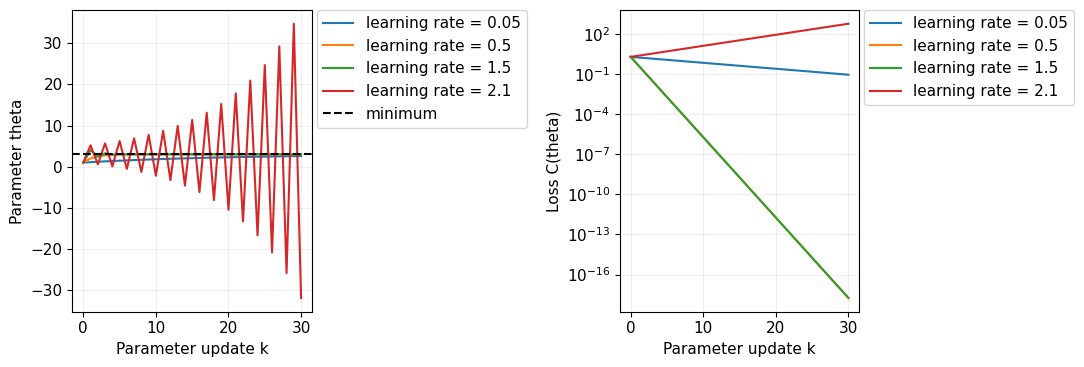

g=-2.000, m=-0.200, v=0.004000
bias-corrected m=-2.000, v=4.000
theta after Adam update = 1.09999984


In [14]:
# A controlled scalar example, not the fluid surrogate's training result.
import numpy as np
import matplotlib.pyplot as plt
eta_values = [0.05, 0.5, 1.5, 2.1]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for eta in eta_values:
    theta = 1.0
    path = [theta]
    for k in range(30):
        gradient = theta - 3.0
        theta -= eta * gradient
        path.append(theta)
    path = np.asarray(path)
    axes[0].plot(path, label=f"learning rate = {eta}")
    axes[1].semilogy(0.5 * (path - 3.0)**2, label=f"learning rate = {eta}")
axes[0].axhline(3.0, color="black", linestyle="--", label="minimum")
axes[0].set(xlabel="Parameter update k", ylabel="Parameter theta")
axes[1].set(xlabel="Parameter update k", ylabel="Loss C(theta)")
for ax in axes:
    ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0); ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

# One Adam update, using the Keras epsilon-hat convention.
theta, m, v = 1.0, 0.0, 0.0
eta, beta1, beta2, epsilon = 0.1, 0.9, 0.999, 1e-7
k = 1
g = theta - 3.0
m = beta1*m + (1-beta1)*g
v = beta2*v + (1-beta2)*g*g
m_hat, v_hat = m/(1-beta1**k), v/(1-beta2**k)
alpha = eta*np.sqrt(1-beta2**k)/(1-beta1**k)
theta -= alpha*m/(np.sqrt(v)+epsilon)
print(f"g={g:.3f}, m={m:.3f}, v={v:.6f}")
print(f"bias-corrected m={m_hat:.3f}, v={v_hat:.3f}")
print(f"theta after Adam update = {theta:.8f}")
assert np.isclose(theta, 1.099999841886367, rtol=0, atol=1e-12)


### Training controls: change one choice at a time

The next cell defines the settings used by the DNN training call. `LEARNING_RATE` is Adam's base rate; `BATCH_SIZE` sets samples per update; `MAX_EPOCHS` caps passes through training data; `PATIENCE` counts epochs without improved validation loss. `HIDDEN_UNITS` gives the widths of the two hidden layers. `TRAINING_SEED` controls initialization and shuffling for paired comparisons.

First retain these defaults. A dense layer with $n_{\mathrm{in}}$ inputs and $n_{\mathrm{out}}$ output neurons has $(n_{\mathrm{in}}+1)n_{\mathrm{out}}$ trainable numbers: $n_{\mathrm{in}}n_{\mathrm{out}}$ weights and $n_{\mathrm{out}}$ biases. The printed parameter count includes both. Changing a width or batch size updates the counts automatically. A weight or bias is a trainable parameter; a width or learning rate is a hyperparameter. The displayed elapsed time includes DNN construction and training.


### A depth control must change the actual computational graph

`HIDDEN_UNITS=(32,)` creates one hidden layer; `(32,32)` creates two; `(32,32,32)` creates three. Each layer computes $h^{(l)}=\sigma(W^{(l)}h^{(l-1)}+b^{(l)})$. Here $h^{(0)}$ contains four **training-standardized** inputs, $W$ and $b$ are trainable weights/biases, and `ACTIVATION` selects $\sigma$. The final linear layer produces one standardized $Q^*$; inverse scaling restores its physical teaching units.

The parameter count is $\sum_l (n_{l-1}+1)n_l$, including biases. The assertion after model construction must agree with that formula. Changing width affects both approximation capacity and cost; changing depth adds compositions rather than merely adding parameters. Keep the seed, split and maximum update budget fixed for the first comparison, select with validation loss, then inspect the frozen test once. More layers can optimize worse; neither lower training loss nor a smoother curve proves better generalization.

**Engineering check:** compare `(32,)`, `(32,32)`, `(32,32,32)`. Record parameter count, actual epochs, elapsed CPU time, validation MSE and the signed fixed-condition profile error. The initial comparison is against noisy synthetic labels, while the profile uses the noise-free formula. These are different error targets. No result in this notebook validates a physical rarefied-flow solver.


In [15]:
LEARNING_RATE = 1e-3
BATCH_SIZE = 64
MAX_EPOCHS = 500
PATIENCE = 30
HIDDEN_UNITS = (32, 32)
TRAINING_SEED = 7
ACTIVATION = "tanh"
assert HIDDEN_UNITS and all(isinstance(w, int) and w > 0 for w in HIDDEN_UNITS)

layer_widths = [X_train_s.shape[1], *HIDDEN_UNITS, y_train_s.shape[1]]
parameter_count = sum((inputs+1)*outputs
                      for inputs, outputs in zip(layer_widths[:-1], layer_widths[1:]))
updates_per_epoch = (len(X_train_s)+BATCH_SIZE-1)//BATCH_SIZE
print("Layer widths:", layer_widths)
print("Trainable weights and biases:", parameter_count)
print("Updates per epoch:", updates_per_epoch)
print("Maximum parameter updates:", MAX_EPOCHS*updates_per_epoch)


def build_surrogate(hidden_units, activation="tanh", input_dim=4, output_dim=1):
    """The tuple controls every hidden layer: (32,) and (32,32,32) are different depths."""
    if not hidden_units or any(not isinstance(w, int) or w <= 0 for w in hidden_units):
        raise ValueError("hidden_units must contain positive integer widths")
    return keras.Sequential([layers.Input(shape=(input_dim,)),
        *[layers.Dense(width, activation=activation) for width in hidden_units],
        layers.Dense(output_dim, activation="linear")])


Layer widths: [4, 32, 32, 1]
Trainable weights and biases: 1249
Updates per epoch: 55
Maximum parameter updates: 27500


In [16]:
import time
keras.utils.set_random_seed(TRAINING_SEED)
training_started = time.perf_counter()
model = build_surrogate(HIDDEN_UNITS, ACTIVATION)

assert model.count_params() == parameter_count
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="mse",
    metrics=["mae"]
)

callback = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=PATIENCE, restore_best_weights=True
)

history = model.fit(
    X_train_s, y_train_s,
    validation_data=(X_val_s, y_val_s),
    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[callback],
    verbose=0
)

print("Training finished after", len(history.history["loss"]), "epochs")

training_seconds = time.perf_counter()-training_started
print(f"DNN setup and training elapsed: {training_seconds:.2f} s")


Training finished after 414 epochs
DNN setup and training elapsed: 95.72 s


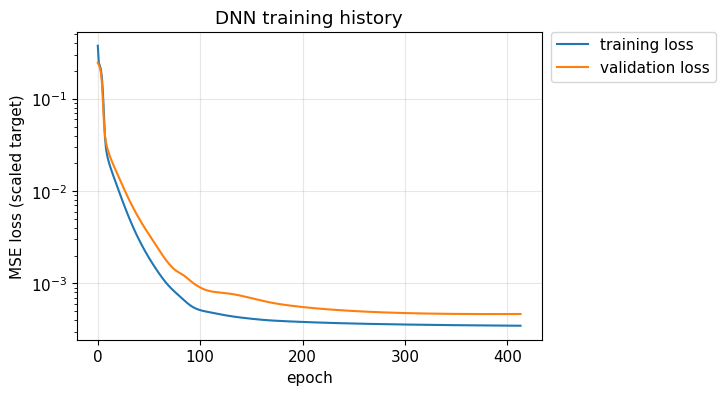

In [17]:

plt.figure()
plt.semilogy(history.history["loss"], label="training loss")
plt.semilogy(history.history["val_loss"], label="validation loss")
plt.xlabel("epoch")
plt.ylabel("MSE loss (scaled target)")
plt.title("DNN training history")
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0)
plt.grid(True, alpha=0.3)
plt.show()


In [18]:

y_pred_s = model.predict(X_test_s, verbose=0)
y_pred = scaler_y.inverse_transform(y_pred_s)

dnn_metrics = metrics(y_test, y_pred)
print("DNN metrics (RMSE, MAE, RelL2):", dnn_metrics)


DNN metrics (RMSE, MAE, RelL2): (np.float64(0.012506203257738727), 0.009806597605347633, np.float32(0.011427424))



## 11. Numerical comparison


In [19]:

summary = pd.DataFrame(
    [poly_metrics, knn_metrics, dnn_metrics],
    columns=["RMSE", "MAE", "Relative L2"],
    index=["Polynomial", "KNN/local", "DNN"]
)
summary


,RMSE,MAE,Relative L2
Polynomial,0.086438,0.069087,0.078982
KNN/local,0.070216,0.043786,0.064159
DNN,0.012506,0.009807,0.011427


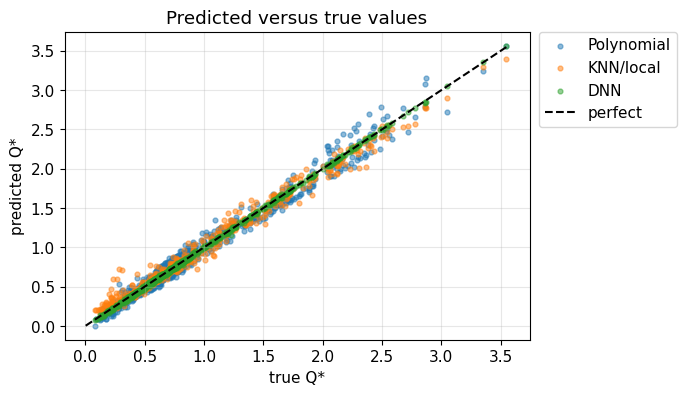

In [20]:

plt.figure()
plt.scatter(y_test, poly_pred, s=12, alpha=0.5, label="Polynomial")
plt.scatter(y_test, knn_pred, s=12, alpha=0.5, label="KNN/local")
plt.scatter(y_test, y_pred, s=12, alpha=0.5, label="DNN")
lo = min(y_test.min(), y_pred.min(), poly_pred.min(), knn_pred.min())
hi = max(y_test.max(), y_pred.max(), poly_pred.max(), knn_pred.max())
plt.plot([lo, hi], [lo, hi], "k--", label="perfect")
plt.xlabel("true Q*")
plt.ylabel("predicted Q*")
plt.title("Predicted versus true values")
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0)
plt.grid(True, alpha=0.3)
plt.show()



## 12. Physical validation checks

### Check 1: positivity


In [21]:

negative_count = np.sum(y_pred.reshape(-1) < 0)
print("Number of negative DNN predictions:", negative_count, "out of", len(y_pred))


Number of negative DNN predictions: 0 out of 750


### Check 2: pressure-ratio monotonicity

For fixed $Kn$, $\alpha$, and $\Theta$, the synthetic function should increase as $\Pi$ increases.

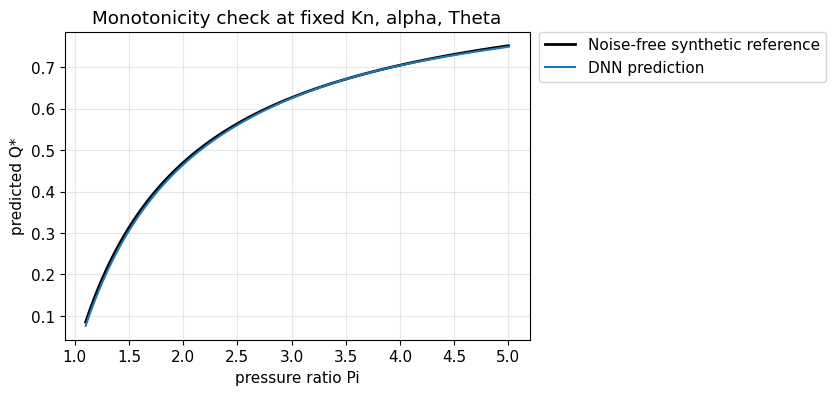

Number of monotonicity violations: 0


In [22]:

fixed_logKn = -2.0
fixed_alpha = 0.85
fixed_Theta = 1.0
Pi_grid = np.linspace(1.1, 5.0, 100)
X_mono = np.column_stack([
    np.full_like(Pi_grid, fixed_logKn),
    np.full_like(Pi_grid, fixed_alpha),
    Pi_grid,
    np.full_like(Pi_grid, fixed_Theta)
]).astype("float32")

X_mono_s = scaler_X.transform(X_mono)
Q_mono_pred = scaler_y.inverse_transform(model.predict(X_mono_s, verbose=0)).reshape(-1)
violations = np.sum(np.diff(Q_mono_pred) < -1e-5)

Q_mono_reference = synthetic_Q(np.full_like(Pi_grid, fixed_logKn), fixed_alpha,
                               Pi_grid, fixed_Theta, noise_std=0.0, seed=0)
plt.figure()
plt.plot(Pi_grid, Q_mono_reference, color="black", lw=2,
         label="Noise-free synthetic reference")
plt.plot(Pi_grid, Q_mono_pred, label="DNN prediction")
plt.xlabel("pressure ratio Pi")
plt.ylabel("predicted Q*")
plt.title("Monotonicity check at fixed Kn, alpha, Theta")
plt.grid(True, alpha=0.3)
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0)
plt.show()

print("Number of monotonicity violations:", violations)


### Compare physical profiles, not only aggregate errors

Hold $\alpha=0.85$, $\Pi=3$ and $\Theta=1$ fixed and vary $Kn$. Each model is evaluated at the same feature vectors. The black curve is the noise-free **synthetic formula**, while the training targets included noise. The polynomial and nearest-neighbor pipelines accept original feature units; the DNN uses the training scalers.

Look for changes in slope, bias near regime boundaries and departures from the reference. Low aggregate test error can coexist with a poor local profile. This one-dimensional slice is an additional diagnostic; it does not cover every combination of the four inputs.


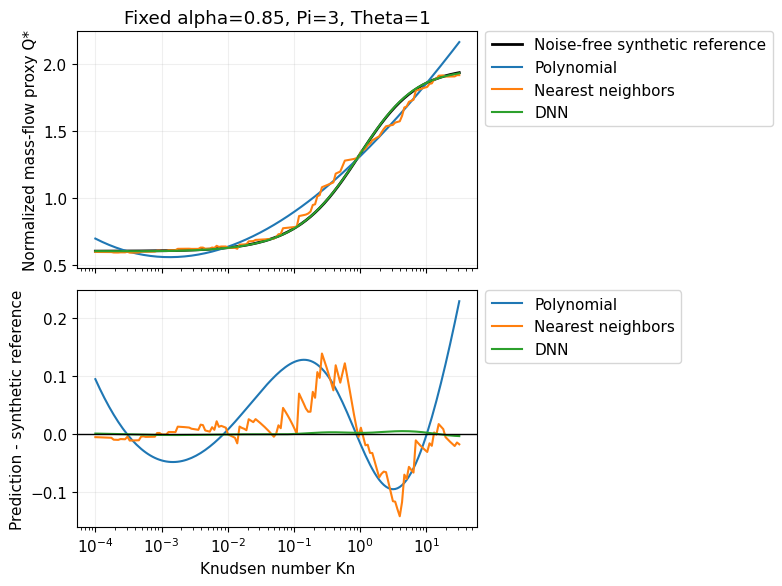

In [23]:
profile_logKn = np.linspace(-4.0, 1.5, 160)
profile_X = np.column_stack([profile_logKn,
                            np.full(160, 0.85),
                            np.full(160, 3.0),
                            np.full(160, 1.0)]).astype("float32")
profile_reference = synthetic_Q(*profile_X.T, noise_std=0.0, seed=0)
profile_predictions = {
    "Polynomial": poly_model.predict(profile_X).reshape(-1),
    "Nearest neighbors": knn_model.predict(profile_X).reshape(-1),
    "DNN": scaler_y.inverse_transform(
        model.predict(scaler_X.transform(profile_X), verbose=0)).reshape(-1)
}
fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
axes[0].plot(10**profile_logKn, profile_reference, color="black", lw=2,
             label="Noise-free synthetic reference")
for name, values in profile_predictions.items():
    axes[0].plot(10**profile_logKn, values, label=name)
    axes[1].plot(10**profile_logKn, values-profile_reference, label=name)
axes[1].axhline(0.0, color="black", lw=1)
axes[0].set(ylabel="Normalized mass-flow proxy Q*",
            title="Fixed alpha=0.85, Pi=3, Theta=1")
axes[1].set(xlabel="Knudsen number Kn", ylabel="Prediction - synthetic reference")
for ax in axes:
    ax.set_xscale("log"); ax.grid(alpha=0.2); ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0)
fig.tight_layout(); plt.show()



### Check 3: regime-wise RMSE


In [24]:

regime_rows = []
for reg in ["continuum", "slip", "transition", "free molecular"]:
    mask = (reg_test == reg)
    if mask.sum() > 0:
        regime_rows.append((reg, mask.sum(), *metrics(y_test[mask], y_pred[mask])))

regime_table = pd.DataFrame(regime_rows, columns=["regime", "N", "RMSE", "MAE", "Relative L2"])
regime_table


,regime,N,RMSE,MAE,Relative L2
0,continuum,144,0.010841,0.008539,0.019292
1,slip,286,0.012240,0.009836,0.020051
2,transition,253,0.013331,0.010228,0.009702
3,free molecular,67,0.013697,0.010815,0.006841



## 13. Extrapolation experiment

Train only on continuum + slip data and test in transition + free-molecular regimes.  This intentionally creates a difficult extrapolation problem.


The validation subset in this experiment is also drawn from the low-Knudsen-number training range. Early stopping therefore selects weights for performance within that range; it cannot detect high-Knudsen-number extrapolation error. The high-range test is evaluated afterward. Do not repeatedly tune the model on those test results and still describe them as an untouched final test.


In [25]:

mask_train_low = X[:,0] <= -1.0      # log10(Kn) <= -1, mostly continuum/slip
mask_test_high = X[:,0] > -1.0       # transition/free molecular

X_low = X[mask_train_low]
y_low = y[mask_train_low]
X_high = X[mask_test_high]
y_high = y[mask_test_high]

X_low_train, X_low_val, y_low_train, y_low_val = train_test_split(
    X_low, y_low, test_size=0.25, random_state=123
)

scaler_X_low = StandardScaler().fit(X_low_train)
scaler_y_low = StandardScaler().fit(y_low_train)

X_low_train_s = scaler_X_low.transform(X_low_train)
X_low_val_s = scaler_X_low.transform(X_low_val)
X_high_s = scaler_X_low.transform(X_high)
y_low_train_s = scaler_y_low.transform(y_low_train)
y_low_val_s = scaler_y_low.transform(y_low_val)

extrap_model = keras.Sequential([
    layers.Input(shape=(4,)),
    layers.Dense(32, activation="tanh"),
    layers.Dense(32, activation="tanh"),
    layers.Dense(1, activation="linear")
])
extrap_model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
extrap_hist = extrap_model.fit(
    X_low_train_s, y_low_train_s,
    validation_data=(X_low_val_s, y_low_val_s),
    epochs=400,
    batch_size=64,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=25, restore_best_weights=True)],
    verbose=0
)

y_high_pred = scaler_y_low.inverse_transform(extrap_model.predict(X_high_s, verbose=0))
print("Extrapolation metrics on log10(Kn)>-1:", metrics(y_high, y_high_pred))


Extrapolation metrics on log10(Kn)>-1: (np.float64(0.6011163369861607), 0.4459298253059387, np.float32(0.39459336))


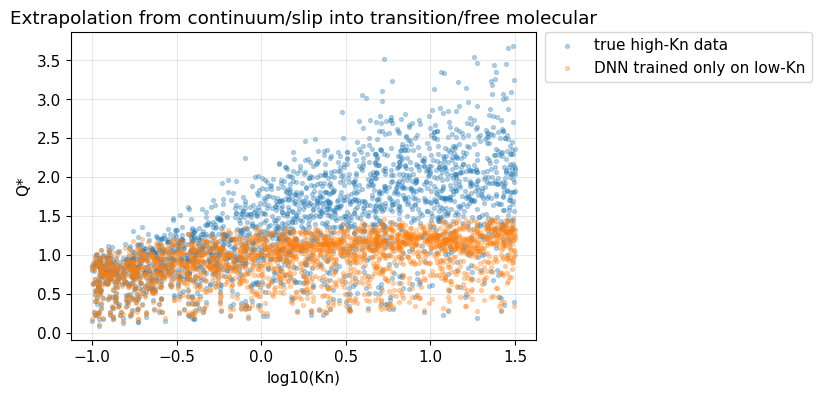

In [26]:

plt.figure()
plt.scatter(X_high[:,0], y_high, s=8, alpha=0.3, label="true high-Kn data")
plt.scatter(X_high[:,0], y_high_pred, s=8, alpha=0.3, label="DNN trained only on low-Kn")
plt.xlabel("log10(Kn)")
plt.ylabel("Q*")
plt.title("Extrapolation from continuum/slip into transition/free molecular")
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0)
plt.grid(True, alpha=0.3)
plt.show()



### Final reflection for your report

Answer these questions:

1. Which model had the lowest test error in the random split?
2. Did the DNN behave physically in the monotonicity and positivity checks?
3. What happened in the extrapolation experiment?
4. Why is extrapolation across Knudsen regimes risky?
5. How would DSMC noise make this task harder?


## Student investigation: evidence to submit

1. **One sample:** derive the factor $1-5.64\eta$ and explain all four trajectories in the neuron experiment. Report the first updated weights, bias, prediction and loss for $\eta=0.05$.
2. **Data handling:** give the shapes and roles of training, validation and test arrays. Explain why fitting a scaler on all 5000 samples would leak information.
3. **Adam rate:** compare `LEARNING_RATE` values $10^{-4}$, $10^{-3}$ and $10^{-2}$, keeping the split, architecture, batch size and epoch budget fixed. For each rate rerun the DNN cell, which constructs a fresh optimizer and resets the seed. Retain the training/validation histories before the next run. Compare paired seeds 7, 17 and 27 if time permits. Multiple fits can be substantially slower than the default single fit.
4. **Select before testing:** choose a rate from validation histories and report its best validation epoch, epochs executed and elapsed training time. Then evaluate the selected model on the test set. Do not repeatedly select on test errors.
5. **Flow behavior:** submit the fixed-parameter $Q^*(Kn)$ profiles and signed differences from the synthetic reference. Explain one visible difference between models, alongside the error table and pressure-ratio monotonicity check.
6. **New regime:** explain why validation drawn from low-$Kn$ data cannot certify high-$Kn$ predictions. Distinguish interpolation error, extrapolation error and disagreement with real physics.

Report the runtime's TensorFlow version, settings, seeds, plots and numerical errors. A smooth curve or a small training loss alone is not sufficient evidence of accuracy.


## Article-output contract

<!-- MIE690A article-aligned validation v3 -->

**Role:** Foundational or supporting notebook; see ARTICLE_FIGURE_MAP.md for its evidence dependency.

All manuscript-facing figures must be generated from retained numerical/model outputs through the documented notebook or shared helper, saved under `results/`, and accompanied by machine-readable metrics. Do not redraw curves by eye or substitute a screenshot for a solver-to-reference comparison. The complete ownership table and exact output filenames are in [`ARTICLE_FIGURE_MAP.md`](../../ARTICLE_FIGURE_MAP.md).


<!-- FLOWMLLAB_EARLY_TEACHING_20261120 -->
